<h1>Multivariate Analysis</h1>

Multivariate analysis means analyzing three or more variables together to understand more complex relationships in a dataset.
    
Example, customer churn may depend on monthly charges, tenure, contract type, and payment method together.
    


In [8]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [9]:
df = pd.read_csv('customer_churn.csv')
df.head()

,CustomerID,Age,Gender,TenureYears,MonthlyCharges,TotalCharges,ContractType,InternetService,PaymentMethod,SeniorCitizen,SupportCalls,StreamingService,PaperlessBilling,Churn
0,CUST00001,56.0,Female,0,20.41,131.92,One year,DSL,Bank transfer,No,3,No,Yes,Yes
1,CUST00002,69.0,Male,9,21.10,2394.45,Two year,DSL,Credit card,Yes,1,Yes,No,No
2,CUST00003,46.0,Female,3,61.66,2755.45,Two year,DSL,Bank transfer,No,3,Yes,No,No
3,CUST00004,32.0,Male,8,35.50,3796.58,Month-to-month,No,Credit card,No,2,No,No,No
4,CUST00005,60.0,Male,9,86.45,10188.80,Two year,Fiber optic,Electronic check,Yes,3,No,Yes,Yes


In [10]:
# Cleaning categorical text columns

df['ContractType'] = df['ContractType'].str.replace('Month to month', 'Month-to-month')
df['InternetService'] = df['InternetService'].str.replace('fiber optic', 'Fiber optic')
df['Gender'] = df['Gender'].str.capitalize()

<h2>Correlation Matrix</h2>
    
A correlation matrix shows the correlation coefficients between pairs of numerical features.
    
The values range from -1 to +1.
    
- +1: Perfect positive linear correlation.
- -1: Perfect negative linear correlation.
- 0: No linear correlation.

Example:

Evaluating how customer age, account tenure, monthly charges, and total revenue co-vary across telecommunication subscribers.

<h3>AI/ML Usage</h3>
    
Used during exploratory data analysis (EDA) and feature selection to detect collinear features that cause instability in linear regression or logistic regression models.

In [11]:
# Convert Churn to binary for correlation analysis

df['Churn_Numeric'] = df['Churn'].apply(lambda x: 1 if x == 'Yes' else 0)

In [12]:
num_cols = ['Age', 'TenureYears', 'MonthlyCharges', 'TotalCharges', 'SupportCalls', 'Churn_Numeric']
corr = df[num_cols].corr()
print("\nCorrelation Matrix:")
print(corr.round(3))


Correlation Matrix:
                  Age  TenureYears  MonthlyCharges  TotalCharges  \
Age             1.000        0.018          -0.007         0.016   
TenureYears     0.018        1.000          -0.015         0.760   
MonthlyCharges -0.007       -0.015           1.000         0.552   
TotalCharges    0.016        0.760           0.552         1.000   
SupportCalls    0.008        0.013          -0.024        -0.006   
Churn_Numeric   0.005       -0.115           0.002        -0.089   

                SupportCalls  Churn_Numeric  
Age                    0.008          0.005  
TenureYears            0.013         -0.115  
MonthlyCharges        -0.024          0.002  
TotalCharges          -0.006         -0.089  
SupportCalls           1.000          0.025  
Churn_Numeric          0.025          1.000  


<h2>Heatmap</h2>

A heatmap uses colors to represent numerical values. We often use it to visualize a correlation matrix.

Why use it? It helps us quickly identify strong positive and negative correlations without reading every number.

Example:

Visualizing gene expression levels across multiple biological samples or mapping high-volume customer transaction periods by day and hour.

<h3>AI/ML Usage</h3>

Accelerates feature diagnostic workflows by allowing data scientists to instantly spot strong correlation clusters, multicollinearity, or missing value patterns across dozens of features.

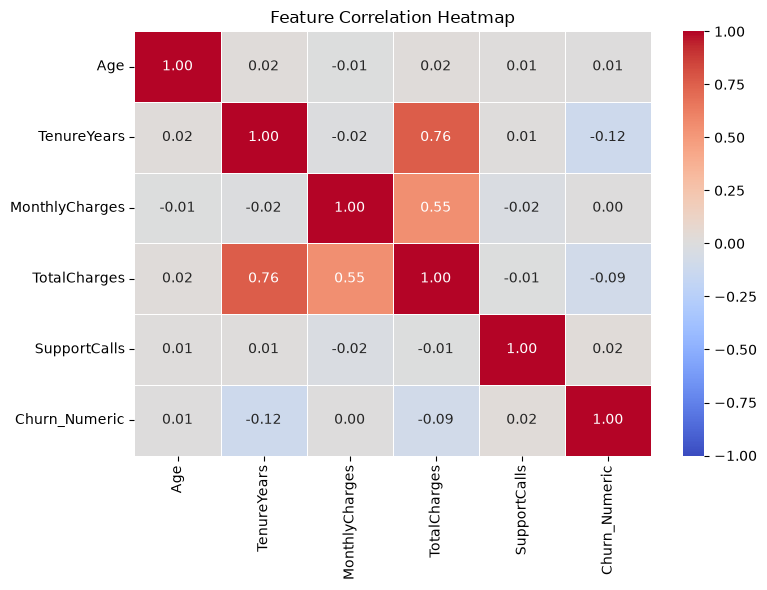

In [13]:
plt.figure(figsize=(8, 6))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1, linewidths=0.5)
plt.title('Feature Correlation Heatmap')
plt.tight_layout()
plt.show()

- Purpose: Visualizes a matrix of pairwise correlation coefficients (r) across all numerical variables using a color spectrum bounded between -1.0 and +1.0.
- Interpretation:
* Warm/Red Shades ($r > 0.5$): Indicate strong positive linear relationships.
* Cool/Blue Shades ($r < -0.5$): Indicate strong negative linear relationships.
* Neutral/White Shades ($r \approx 0$): Indicate no linear dependency.
- Churn Dataset Findings: Highlights a strong positive correlation between TenureYears and TotalCharges (r = 0.76) and a moderate correlation between MonthlyCharges and TotalCharges (r = 0.55) Features like Age and SupportCalls show virtually zero linear correlation with billing variables (|r| < 0.03)

<h2>Pair Plot</h2>

A pair plot displays relationships between multiple numerical features using scatter plots, along with each feature's distribution on the diagonal.

Example:

Comparing real estate attributes (price, square footage, age, distance to city center) grouped by property type.

<h3>AI/ML Usage</h3>
    
Helps identify non-linear relationships, multi-modal class overlaps, and spatial clustering across target classes prior to selecting linear vs. tree-based classifiers.

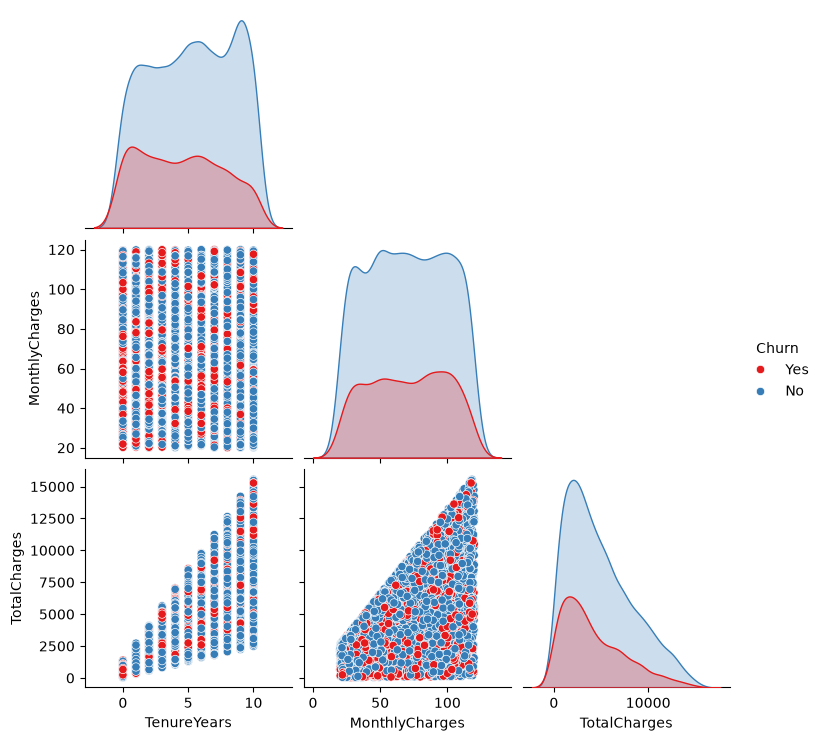

In [14]:
sns.pairplot(
    df[['TenureYears', 'MonthlyCharges', 'TotalCharges', 'Churn']], 
    hue='Churn', 
    palette='Set1', 
    corner=True
)
plt.show()

<h2>Multiple Feature Relationships</h2>

This means investigating how several features relate to one another or to a target variable.

Example: Predicting house prices using area, number of bedrooms, and house age

<h3>AI/ML Usage</h3>

Enables understanding of multi-way conditional dependencies to design proper segmentation logic or rule-based expert engines.

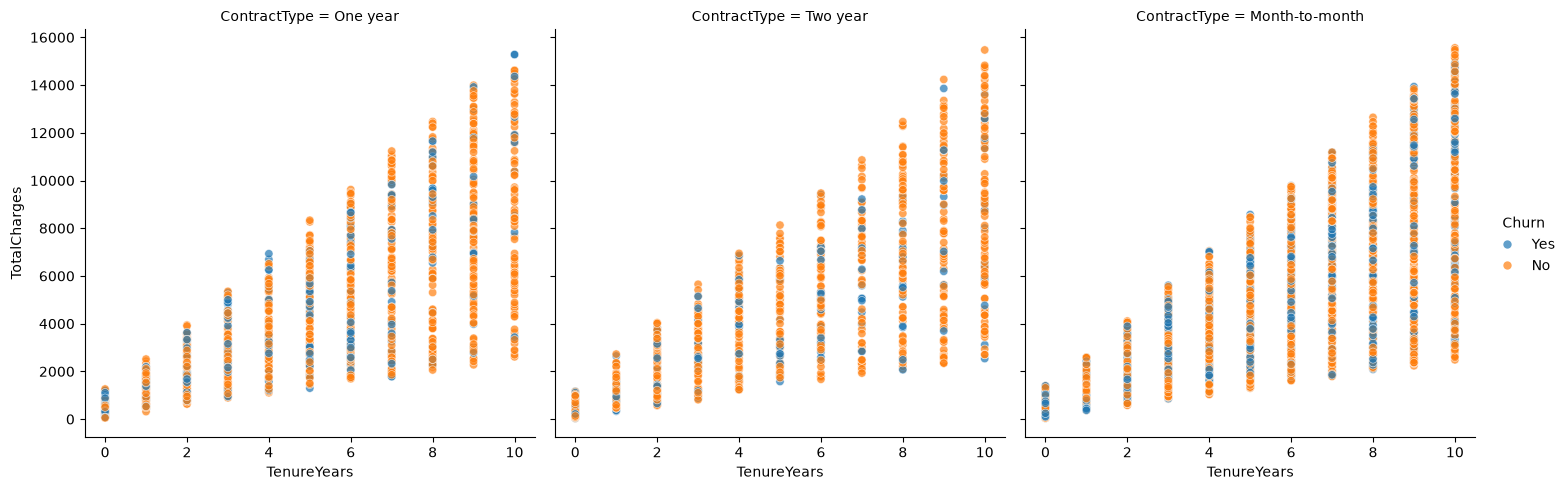

In [15]:
# Faceted scatter plot exploring 4 variables simultaneously
sns.relplot(
    data=df,
    x='TenureYears',
    y='TotalCharges',
    hue='Churn',
    col='ContractType',
    kind='scatter',
    alpha=0.7
)
plt.show()

<h2>Feature Interactions</h2>

Meaning: A feature interaction occurs when the effect of one feature on the target depends on the value of another feature.
    
Example: The impact of house area on price may be different for houses in premium locations

<h3>AI/ML Usage</h3>

Explicitly engineered into linear/logistic models via product terms (x1 x x2) or automatically captured by non-linear algorithms like Decision Trees and Gradient Boosted Trees (XGBoost/LightGBM).

In [16]:
df['Tenure_x_Monthly'] = df['TenureYears'] * df['MonthlyCharges']
df['Calls_per_TenureYear'] = df['SupportCalls'] / (df['TenureYears'] + 1)

In [17]:
# Check interaction correlation with churn target

df['Churn_Numeric'] = (df['Churn'] == 'Yes').astype(int)
print(df[['Tenure_x_Monthly', 'Calls_per_TenureYear', 'Churn_Numeric']].corr()['Churn_Numeric'])

Tenure_x_Monthly       -0.089881
Calls_per_TenureYear    0.088432
Churn_Numeric           1.000000
Name: Churn_Numeric, dtype: float64


<h2>Numerical Feature Relationships</h2>

This focuses specifically on understanding how numerical features are related, including linear and nonlinear patterns.
    
Examples:
- Age vs Salary
- Area vs House Price
- Experience vs Salary
- Monthly Charges vs Total Charges

<h3>AI/ML Usage</h3>

Directly informs data preprocessing steps, such as applying logarithmic transforms to skewed features, removing redundant features, or fitting Polynomial Regression models.

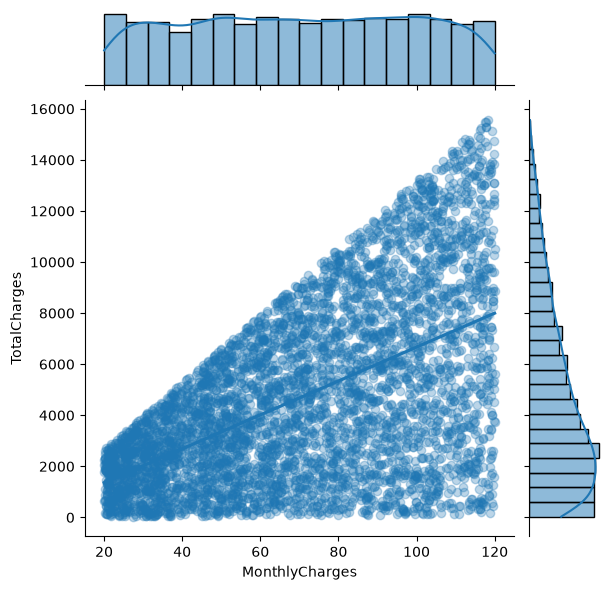

In [18]:
sns.jointplot(
    data=df, 
    x='MonthlyCharges', 
    y='TotalCharges', 
    kind='reg', 
    scatter_kws={'alpha':0.3}
)
plt.show()